<div align="center"><img src="https://github.com/user-attachments/assets/5d3a38ab-b20c-4103-b401-cddc112bfac8" width="300" alt="NOVA IMS Logo">

  <br>
  <br>
  <b>Master in Data Science and Advanced Analytics</b>

  <b>Computational Intelligence for Optimization </b>

  2025–2026

  <h1><b> Vermeer’s <i>Girl with a pearl earing</i>: 100 triangles Challenge <b></h1>
</div>



### <span style="color:#89AC76;">C22_Natural_Selection | Members</span>

<table>
  <thead style="color:#89AC76;">
    <tr>
      <th>Name</th>
      <th>Student ID</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Afonso Hermenegildo</td>
      <td>20221958</td>
    </tr>
    <tr>
      <td>André Ferreira</td>
      <td>20250398</td>
    </tr>
    <tr>
      <td>Marco Martins</td>
      <td>20221951</td>
    </tr>
    <tr>
      <td>Maria Francisca Gonçalves</td>
      <td>20221942</td>
    </tr>
  </tbody>
</table>

## <span style="color:#89AC76;">Table of Contents</span>


[ADICIONAR!!]

---
<h2 id="chapter1" style="color:#89AC76;">1. Imports</h2>
<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

All libraries used throughout the notebook are imported here. We rely on `Pillow` and `numpy` for image handling, `matplotlib` for visualisation, and `scipy` for statistical testing. The class-provided `library` module is also imported to access the base `Solution` class.

In [6]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), "scripts"))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from scripts.triangle_sol import TriangleSolution
from scripts.ga import genetic_algorithm
from scripts.ga_utils import get_fitness
from scripts.experiments import (
    # REMOVE THESE
    # run_grid_search,
    # print_grid_search_results,
    # plot_grid_search_results,
    
    plot_fitness_history,
)
from operators import (
    # selection
    roulette_wheel_selection,
    rank_based_selection,
    tournament_selection,
    # crossover
    one_point_crossover,
    two_point_crossover,
    uniform_crossover,
    # mutation
    triangle_gaussian_mutation,
    triangle_gaussian_color_mutation,
    triangle_gaussian_vertex_mutation,
    triangle_reset_gene_mutation,
    triangle_reset_mutation,
    triangle_layer_swap_mutation,
)
from scripts.statistical_comparison import run_ga_statistical_comparison
from scripts.statistical_comparison import plot_statistical_comparison

---
<h2 id="chapter2" style="color:#89AC76;">2. Target Image Loading &amp; Inspection</h2>
<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

We load the 300×400 target image and convert it to a NumPy array. Keeping the array in memory as a global constant avoids redundant I/O during fitness evaluations, which are called thousands of times per run.

Image size  : 300 x 400 px
Array shape : (400, 300, 4)


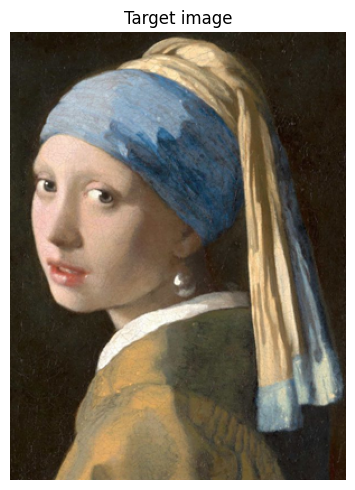

In [8]:
IMG_PATH = "project_info/girl_pearl_earing.png"

target_img = Image.open(IMG_PATH).convert("RGBA")
target_arr = np.array(target_img, dtype=np.int16)

IMG_WIDTH, IMG_HEIGHT = target_img.size   # (width, height) from PIL

print(f"Image size  : {IMG_WIDTH} x {IMG_HEIGHT} px")
print(f"Array shape : {target_arr.shape}")

# Wire the target into TriangleSolution so every instance uses it automatically
TriangleSolution.target_array = target_arr
TriangleSolution.__init__.__defaults__  # sanity-check defaults still present

plt.figure(figsize=(4, 5))
plt.imshow(target_arr)
plt.title("Target image")
plt.axis("off")
plt.tight_layout()
plt.show()

Now, we will check the distribution of our data.

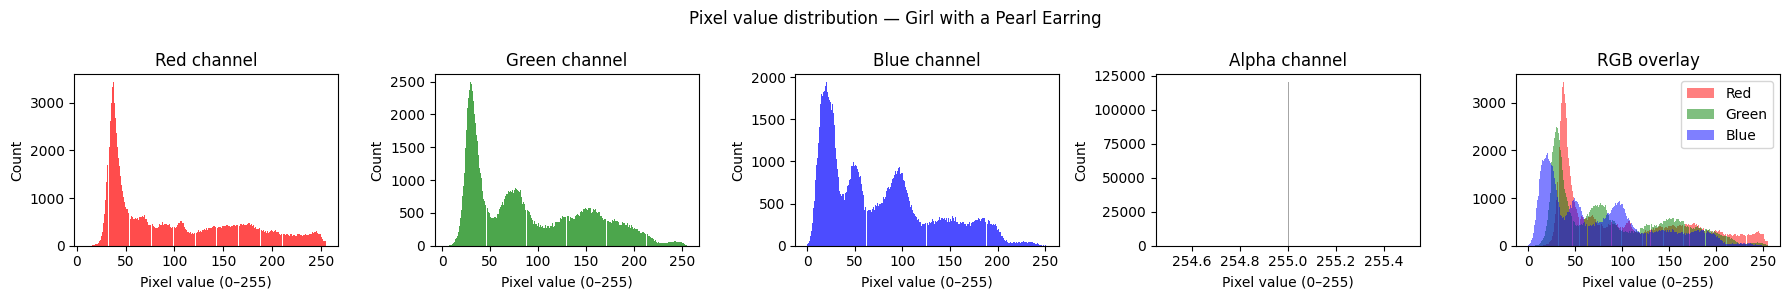

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3))
channels = ['Red', 'Green', 'Blue', 'Alpha']
colors   = ['red', 'green', 'blue', 'gray']

for i, (ch, col) in enumerate(zip(channels, colors)):
    axes[i].hist(target_arr[:, :, i].ravel(), bins=256, color=col, alpha=0.7)
    axes[i].set_title(f'{ch} channel')
    axes[i].set_xlabel('Pixel value (0–255)')
    axes[i].set_ylabel('Count')

# combined RGB only (alpha separate makes the overlay hard to read)
for i, (col, label) in enumerate(zip(['red','green','blue'], ['Red','Green','Blue'])):
    axes[4].hist(target_arr[:, :, i].ravel(), bins=256, color=col, alpha=0.5, label=label)
axes[4].set_title('RGB overlay')
axes[4].set_xlabel('Pixel value (0–255)')
axes[4].legend()

plt.suptitle('Pixel value distribution - Girl with a Pearl Earring')
plt.tight_layout()
plt.show()

---
<h2 id="chapter3" style="color:#89AC76;">3. Solution Representation</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

### Representation - How the solution is encoded

Each individual in the population encodes a candidate image as an ordered sequence of **100 triangles**, drawn sequentially onto a 300×400 canvas — later triangles occlude earlier ones. Each triangle is represented by **10 real-valued genes**.

```
[ x1, y1, x2, y2, x3, y3, Red, Green, Blue, Alpha]
```


| Gene(s) | Variable | Domain |
|---|---|---|
| x₁, y₁, x₂, y₂, x₃, y₃ | Vertex coordinates | [0, 1] (normalised) |
| R, G, B | Fill colour | [0, 255] |
| A | Opacity | [0, 255] |

### Fitness - measurement of quality of the solution
Fitness is the **pixel-wise RMSE** between the rendered image and the target (lower is  better, since this is a minimisation problem):

$$\text{RMSE} = \sqrt{\frac{1}{W \cdot H \cdot 4} \sum_{i,j,c} (\hat{I}_{ijc} - I_{ijc})^2}$$

where $W=300$, $H=400$, and $C=4$ (RGBA channels)


<span style="color:#BA8E23;">

**TEXT ABOVE INSPIRED IN PRATICAL CLASS 3**

</span>

In [3]:
sol = TriangleSolution()

In [4]:
sol = TriangleSolution()
sol.representation

array([289, 343, 245, 356, 200, 165, 220, 215,  66, 239, 170,   9,  76,
       248,  69,  70, 119, 232,   0,  81,  62,  78, 288, 360, 173, 358,
       144,  65,   1, 212, 150, 359,  24, 123, 134, 194, 117, 168, 221,
        17, 129, 167,  94, 248,  11,  85, 116, 161, 130,  24, 248, 343,
       258, 354, 128, 162, 193, 109, 205,  56,  21,  21,  20,  34, 213,
        98,  58, 100, 190,  48, 228, 155, 171, 169, 197, 275,  32, 119,
       101, 137, 143, 213, 165, 296,  86, 361, 225, 100,  74,  39,  44,
       372, 278, 351, 254, 237,  21, 131, 172, 153, 149, 229, 248,  89,
        22, 322, 223, 186, 193, 173, 278, 238,   0, 312,  89, 109,  42,
        97,  58,  47, 160, 198, 283, 328,  39, 116,  69, 128,  82, 197,
       281, 103, 128, 128, 275, 121, 233, 129,  56,  94, 108, 123, 291,
       372, 122,  68, 170, 252, 183,  86, 121, 272, 285, 362, 212,  81,
       146, 134,  14, 100, 268, 310,  27,  60, 270, 225, 249, 182, 176,
       149,  21, 135,  24,  41, 134, 100,  43, 130,  76,  70,  1

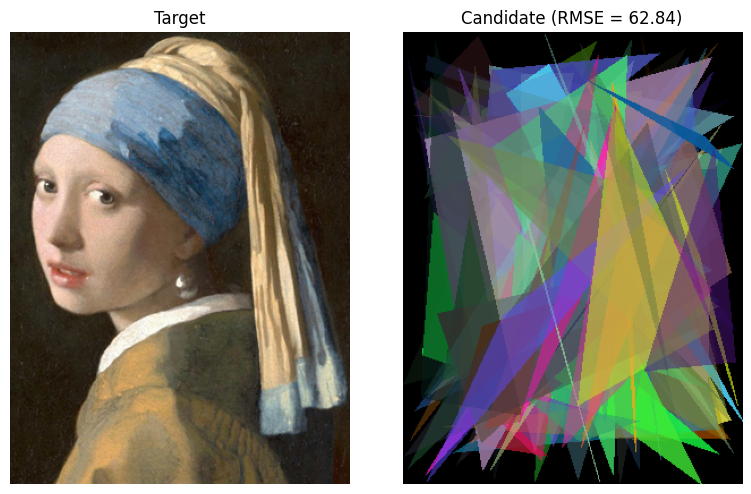

In [5]:
sol.show()

The output generated is a **single random individual**.

<h2 id="chapter4" style="color:#89AC76;">4. Baseline GA Run</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

A single run with sensible defaults to confirm everything works end-to-end.

In [6]:
BASELINE_PARAMS = dict(
    population_size = 50,
    n_generations = 200,
    selection_function = tournament_selection,
    crossover_function = one_point_crossover,
    mutation_function = triangle_gaussian_mutation,
    crossover_rate = 0.9,
    mutation_rate = 0.02,
    mutation_rate_decay = None,
    elitism_n = 2,
    n_jobs = -1,
    verbose = True,
    verbose_every = 25,
)

best_sol, history, avg_history = genetic_algorithm(**BASELINE_PARAMS)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 57.4659 | avg RMSE: 68.1869 | mut rate: 0.02000
Gen   25 | best RMSE: 51.8110 | avg RMSE: 52.2461 | mut rate: 0.02000
Gen   50 | best RMSE: 49.0399 | avg RMSE: 49.3354 | mut rate: 0.02000
Gen   75 | best RMSE: 46.9828 | avg RMSE: 47.3295 | mut rate: 0.02000
Gen  100 | best RMSE: 45.1102 | avg RMSE: 45.4459 | mut rate: 0.02000
Gen  125 | best RMSE: 43.4834 | avg RMSE: 43.7123 | mut rate: 0.02000
Gen  150 | best RMSE: 42.1624 | avg RMSE: 42.3839 | mut rate: 0.02000
Gen  175 | best RMSE: 40.5928 | avg RMSE: 40.9435 | mut rate: 0.02000
Gen  199 | best RMSE: 39.2180 | avg RMSE: 39.5183 | mut rate: 0.02000

Finished. Best RMSE: 39.2180
Best RMSE : 39.2180


<h3 id="chapter4.1" style="color:#89AC76;">4.1 Convergence Plot</h3>

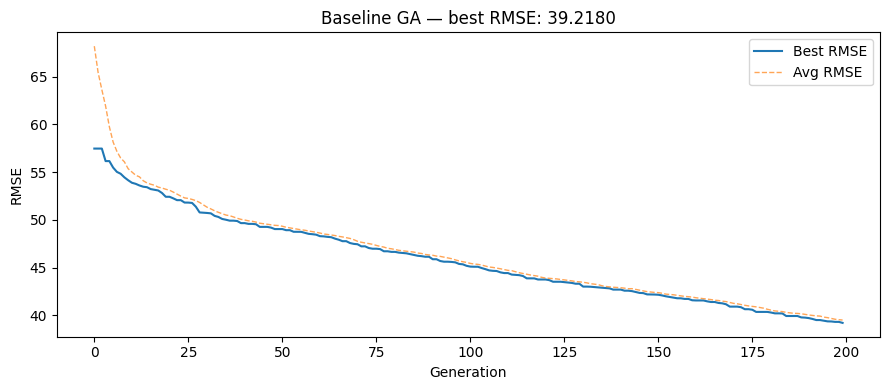

In [7]:
plot_fitness_history(
    history,
    avg_history,
    title=f"Baseline GA — best RMSE: {history[-1]:.4f}",
)

<h2 id="chapter4" style="color:#89AC76;">5. Best Candidate vs. Target </h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

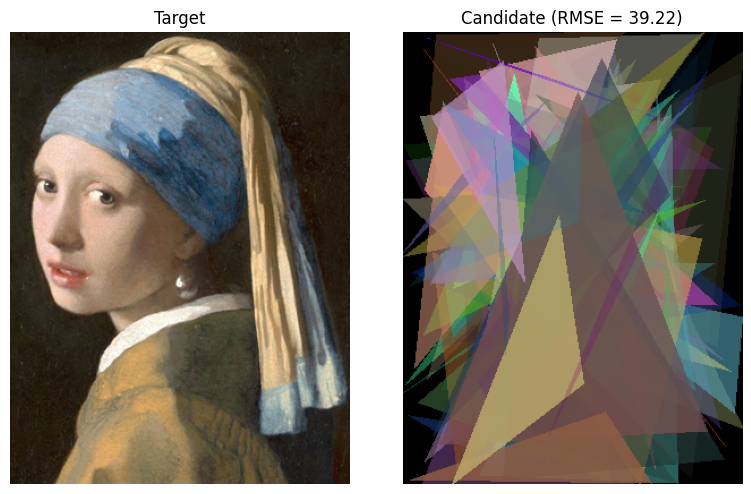

In [8]:
best_sol.show()

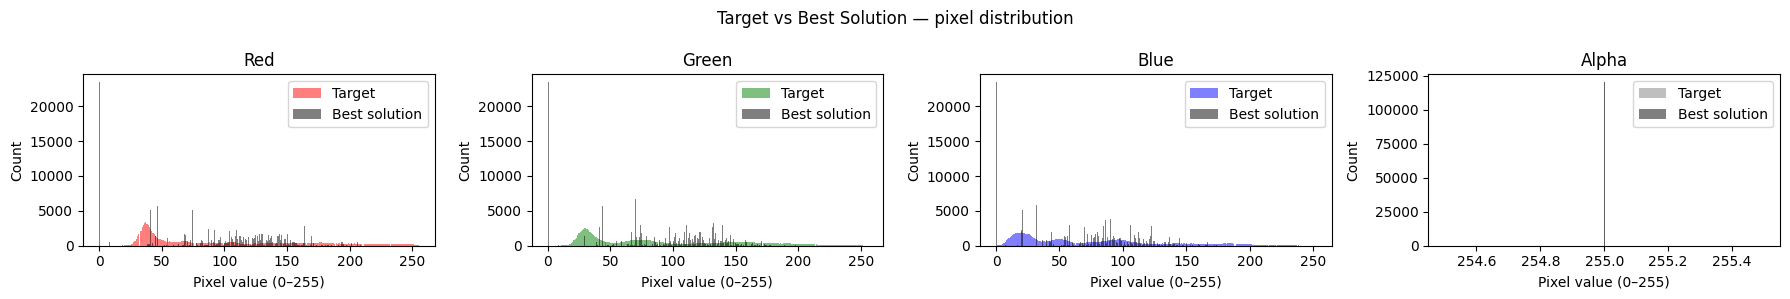

In [ ]:
#### Does this make sense???


rendered_arr = np.array(best_sol.get_image())

fig, axes = plt.subplots(1, 4, figsize=(18, 3))
channels = ['Red', 'Green', 'Blue', 'Alpha']
colors   = ['red', 'green', 'blue', 'gray']

for i, (ch, col) in enumerate(zip(channels, colors)):
    axes[i].hist(target_arr[:,:,i].ravel(),   bins=256, color=col,   alpha=0.5, label='Target')
    axes[i].hist(rendered_arr[:,:,i].ravel(), bins=256, color='black', alpha=0.5, label='Best solution')
    axes[i].set_title(ch)
    axes[i].set_xlabel('Pixel value (0–255)')
    axes[i].set_ylabel('Count')
    axes[i].legend()

plt.suptitle('Target vs Best Solution — pixel distribution')
plt.tight_layout()
plt.show()

<h2 id="chapter4" style="color:#89AC76;">6. Exploring genetic operators</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

Try multiple genetic operators and do statistical tests to compare them and, if applicable get the best parameters for them.

<h3 id="chapter6.1" style="color:#89AC76;">6.1 Selection</h3>

try here all of the selection operators and do statistical tests to compare between them

to choose the size of the tournament selection, we need to take into account the size of the population and what is the resulting selection pressure, so that we can scale up the size of the population at the final run

<h3 id="chapter6.2" style="color:#89AC76;">6.2 Crossover</h3>

try here all of the crossover operators and do statistical tests to compare between them

<h3 id="chapter6.3" style="color:#89AC76;">6.3 Mutation</h3>

In [9]:
mutation_statistical_comparison = run_ga_statistical_comparison(
    "mutation_function",
    [
        triangle_gaussian_mutation,
        triangle_gaussian_color_mutation,
        triangle_gaussian_vertex_mutation,
        triangle_reset_gene_mutation,
        triangle_reset_mutation,
        triangle_layer_swap_mutation
    ]
)


Starting statistical comparison: 180 GA runs × 200 generations = 36,000 total generations



Progress: 100%|██████████| 180/180 [39:59<00:00, 13.33s/ run]


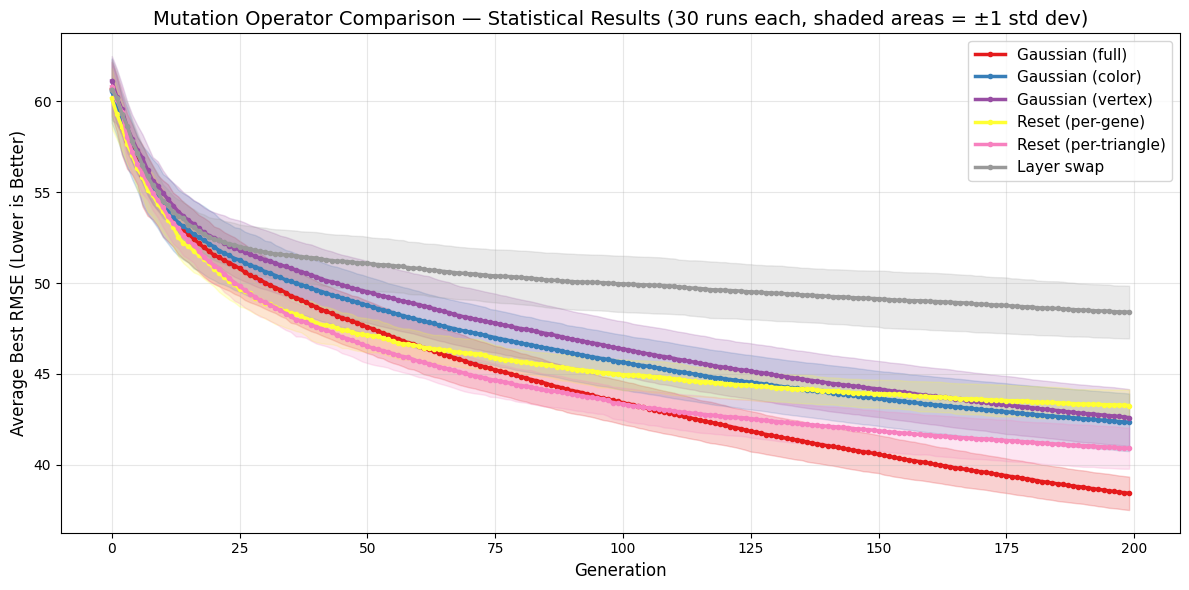

In [10]:
# Visualize mutation statistical results with standard deviation bands
mutation_modes = [
    "Gaussian (full)",
    "Gaussian (color)",
    "Gaussian (vertex)",
    "Reset (per-gene)",
    "Reset (per-triangle)",
    "Layer swap"
]
plot_statistical_comparison(
    mutation_statistical_comparison,
    labels=mutation_modes,
    title="Mutation Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

# print("Final average best RMSE per mutation mode (mean ± std):")
# for idx, (param_value, (avg_fitness, std_fitness)) in enumerate(mutation_runs.items()):
#     print(f"  {mutation_modes[idx]:10s}: {avg_fitness[-1]:.4f} ± {std_fitness[-1]:.4f}")

<h2 id="chapter4" style="color:#89AC76;">8. Save Best Result </h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>


In [ ]:
out_path = "best_result.png"
best_sol.get_image().save(out_path)
print(f"Saved best candidate to: {out_path}")

<span style="color:#BA8E23;">

### <h2><strong>CONFIRM IF IS DONE - UPDATE MAIN</strong></h2>
1. **Hybrid GA + Local Search (Hill Climbing or CMA-ES) - ANDRÉ** - CONFIRMAR SE ESTÁ
	- ran Hill Climbing as a local search after the GA converged, using the GA's best solution as the starting point.

**Afonso** - Passar tudo para o main.


### <h2><strong>MEDIUM PRIORITY</strong></h2>
1. **Smarter initialization** - **Cláudio**
- Sample triangle colours from target pixels
- Cuts early RMSE immediately

### <h2><strong>ANALYSIS AND REPORTING </strong></h2>
1. **Wilcoxon statistical tests with a tournament structure**<br>
Use Wilcoxon signed-rank tests to determine which configuration was statistically significantly better, then ran a tournament-style elimination comparing the winner sequentially against challengers.

mas adaptadoa rmse

2. **Search space size**
Frame as continuous space
Show problem awareness

(as it continuous)


</span>